In [ ]:
#imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from inclusion_financiere.config import RANDOM_STATE, ROOT
from inclusion_financiere.data import get_train_test, CAT_COLS
from inclusion_financiere.pipeline import pipe, logreg
from inclusion_financiere.evaluate import (cv, scoring, summarize_cv, evaluate_baselines, compute_learning_curve, compute_validation_curve,)

X_train, _, y_train, _ = get_train_test() # le test reste sous scellé : on l’ignore avec _

In [ ]:
#trois modèles de référence
res = evaluate_baselines(X_train, y_train)
def ms(mean, std):
    return f'{mean:.3f} ± {std:.3f}'

tableau = pd.DataFrame({
    'modèle': res['model'],
    'PR-AUC val': [ms(m, s) for m, s in zip(res['validation_pr_auc_mean'],res['validation_pr_auc_std'])],
    'PR-AUC train': res['train_pr_auc_mean'].round(3),
    'ROC-AUC val': [ms(m, s) for m, s in zip(res['validation_roc_auc_mean'], res['validation_roc_auc_std'])],
    'Brier val': res['validation_brier_mean'].round(4),
    'Accuracy val': res['validation_acc_mean'].round(3),
    'Temps (s)': res['fit_time_mean'].round(2),
})
tableau

Évaluation : Dummy
Évaluation : Logistic Regression sans nouvelles variables
Évaluation : Logistic Regression avec nouvelles variables
Évaluation : Random Forest


,modèle,PR-AUC val,PR-AUC train,ROC-AUC val,Brier val,Accuracy val,Temps (s)
0,Dummy,0.141 ± 0.000,0.141,0.500 ± 0.000,0.1408,0.859,0.25
1,Logistic Regression sans nouvelles variables,0.559 ± 0.027,0.563,0.848 ± 0.010,0.0872,0.884,0.28
2,Logistic Regression avec nouvelles variables,0.561 ± 0.025,0.566,0.849 ± 0.010,0.0869,0.884,0.45
3,Random Forest,0.478 ± 0.032,0.986,0.806 ± 0.010,0.1014,0.866,2.40


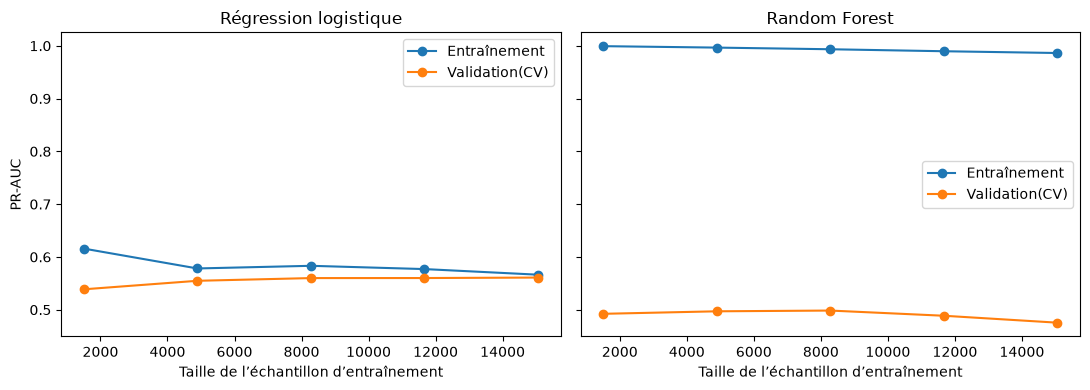

In [ ]:
#courbes d’apprentissage

rf = pipe(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))

lc_log= compute_learning_curve(logreg, X_train, y_train)
lc_rf = compute_learning_curve(rf, X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, lc, titre in zip(axes, [lc_log, lc_rf], ['Régression logistique','Random Forest']):
    ax.plot(lc['train_size'], lc['train_mean'], 'o-', label='Entraînement')
    ax.plot(lc['train_size'], lc['validation_mean'], 'o-', label='Validation(CV)')
    ax.set_title(titre)
    ax.set_xlabel('Taille de l’échantillon d’entraînement')
    ax.legend()
axes[0].set_ylabel('PR-AUC')
plt.tight_layout()
plt.savefig(ROOT / 'reports' / 'figures' / 'courbes_apprentissage.png',
dpi=150)
plt.show()

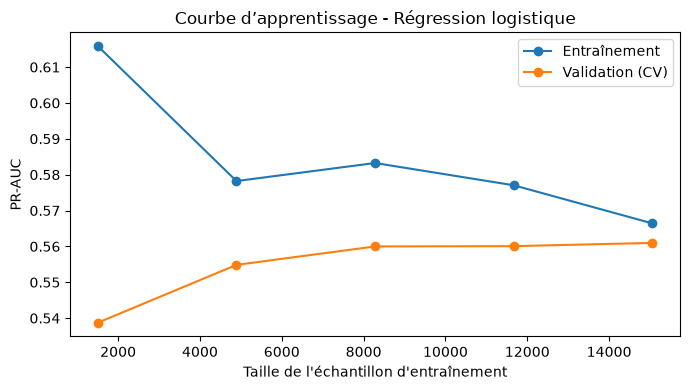

In [7]:
# 1. Calcul de la courbe d'apprentissage
lc_log = compute_learning_curve(logreg, X_train, y_train)

# 2. Création du graphique
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    lc_log['train_size'],
    lc_log['train_mean'],
    'o-',
    label='Entraînement'
)

ax.plot(
    lc_log['train_size'],
    lc_log['validation_mean'],
    'o-',
    label='Validation (CV)'
)

ax.set_title('Courbe d’apprentissage - Régression logistique')
ax.set_xlabel("Taille de l'échantillon d'entraînement")
ax.set_ylabel('PR-AUC')
ax.legend()

plt.tight_layout()

# 3. Enregistrement
plt.savefig(
    ROOT / 'reports' / 'figures' / 'courbe_apprentissage_logreg.png',
    dpi=150
)

plt.show()

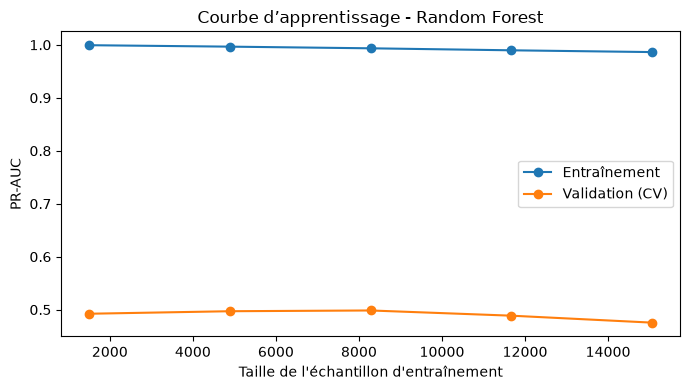

In [8]:
# 1. Construction du modèle
rf = pipe(
    RandomForestClassifier(
        n_estimators=200,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
)

# 2. Calcul de la courbe d'apprentissage
lc_rf = compute_learning_curve(rf, X_train, y_train)

# 3. Création du graphique
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    lc_rf['train_size'],
    lc_rf['train_mean'],
    'o-',
    label='Entraînement'
)

ax.plot(
    lc_rf['train_size'],
    lc_rf['validation_mean'],
    'o-',
    label='Validation (CV)'
)

ax.set_title('Courbe d’apprentissage - Random Forest')
ax.set_xlabel("Taille de l'échantillon d'entraînement")
ax.set_ylabel('PR-AUC')
ax.legend()

plt.tight_layout()

# 4. Enregistrement
plt.savefig(
    ROOT / 'reports' / 'figures' / 'courbe_apprentissage_rf.png',
    dpi=150
)

plt.show()

min_samples_leaf retenu (règle d’une erreur-type) : 50


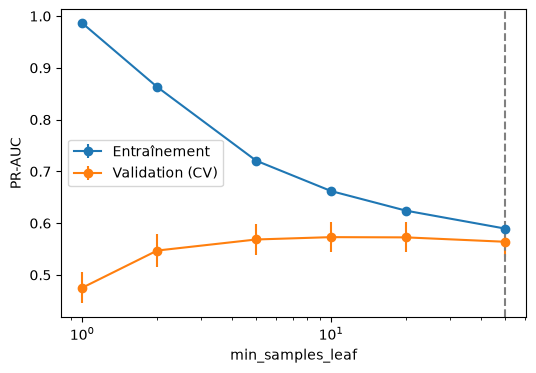

,min_samples_leaf,train_mean,train_std,validation_mean,validation_std
0,1,0.986328,0.000259,0.475308,0.029638
1,2,0.863055,0.003352,0.547095,0.031632
2,5,0.720645,0.004626,0.568474,0.029320
3,10,0.662015,0.005773,0.573003,0.029304
4,20,0.624155,0.005535,0.572540,0.028853
5,50,0.589541,0.005636,0.564052,0.028538


In [4]:
vc, leaf_retenue = compute_validation_curve(rf, X_train, y_train)
print('min_samples_leaf retenu (règle d’une erreur-type) :', leaf_retenue)

plt.figure(figsize=(6, 4))
plt.errorbar(vc['min_samples_leaf'], vc['train_mean'], yerr=vc['train_std'], fmt='o-', label='Entraînement')
plt.errorbar(vc['min_samples_leaf'], vc['validation_mean'], yerr=vc['validation_std'], fmt='o-', label='Validation (CV)')
plt.axvline(leaf_retenue, ls='--', color='gray')
plt.xscale('log')
plt.xlabel('min_samples_leaf')
plt.ylabel('PR-AUC')
plt.legend()
plt.savefig(ROOT / 'reports' / 'figures' / 'courbe_validation_leaf.png', dpi=150)
plt.show()
vc


In [9]:
###les cinq modèles sur les mêmes plis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

modeles = {
    'Random Forest': pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf_retenue, n_jobs=-1,random_state=RANDOM_STATE)),
    'HistGB': pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    'XGBoost': pipe(XGBClassifier(random_state=RANDOM_STATE)),
    'LightGBM': pipe(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
    'CatBoost natif': CatBoostClassifier(cat_features=tuple(CAT_COLS), verbose=0, random_seed=RANDOM_STATE),
}

lignes, scores_plis = [], {}
for nom, modele in modeles.items():
    print('Évaluation :', nom)
    r = cross_validate(modele, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    s = summarize_cv(r, scoring)
    s.insert(0, 'model', nom)
    lignes.append(s)
    scores_plis[nom] = r['test_pr_auc']
    
res_ens = pd.concat(lignes, ignore_index=True)
plis = pd.DataFrame(scores_plis)

Évaluation : Random Forest
Évaluation : HistGB
Évaluation : XGBoost
Évaluation : LightGBM
Évaluation : CatBoost natif


In [10]:
tableau_ens = pd.DataFrame({
    'modèle': res_ens['model'],
    'PR-AUC val': [ms(m, s) for m, s in zip(res_ens['validation_pr_auc_mean'], res_ens['validation_pr_auc_std'])],
    'PR-AUC train': res_ens['train_pr_auc_mean'].round(3),
    'ROC-AUC val': res_ens['validation_roc_auc_mean'].round(3),
    'Brier val': res_ens['validation_brier_mean'].round(4),
    'Temps (s)': res_ens['fit_time_mean'].round(2),
})
    
tableau_ens

,modèle,PR-AUC val,PR-AUC train,ROC-AUC val,Brier val,Temps (s)
0,Random Forest,0.565 ± 0.028,0.590,0.854,0.0876,2.36
1,HistGB,0.568 ± 0.024,0.670,0.857,0.0858,1.05
2,XGBoost,0.543 ± 0.023,0.793,0.844,0.0898,0.89
3,LightGBM,0.565 ± 0.025,0.709,0.854,0.0864,0.52
4,CatBoost natif,0.582 ± 0.024,0.661,0.863,0.0844,132.41


In [11]:
plis.round(4)
plis.sub(plis['Random Forest'], axis=0).round(4)


,Random Forest,HistGB,XGBoost,LightGBM,CatBoost natif
0,0.0,-0.0015,-0.0142,0.0035,0.0221
1,0.0,-0.0083,-0.0465,-0.0148,0.0005
2,0.0,0.0001,-0.0246,-0.0017,0.0135
3,0.0,0.0100,-0.0158,0.0029,0.0212
4,0.0,0.0144,-0.0103,0.0136,0.0292
